# 46. The Linear Algebra of Transformers
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Rotary position embeddings with $d_k=64$ and base $10^4$. Left: the rotation angle $\Delta\omega_k$ (modulo $2\pi$) applied to plane $k$ at offset $\Delta$, for three planes; the first rotates by one radian per position, the last by about one radian per $7500$ positions. Right: the score $q^{T}R_\Delta q$ of a random query with itself shifted by $\Delta$ positions, relative to $\|q\|^2$ (grey), and its average over $2000$ random queries (blue): an oscillating but decaying preference for nearby positions.

<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_85814/1062546375.py:4: SyntaxWarning: invalid escape sequence '\p'
  axs[0].set_xlabel(r"offset $\Delta$"); axs[0].set_ylabel("angle (mod $2\pi$)"); axs[0].legend(fontsize=5.8, frameon=False, loc="upper right")


Text(0, 0.5, 'relative score')

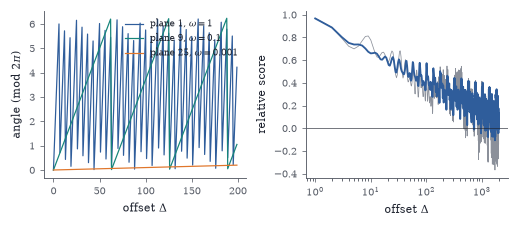

In [2]:
dk = 64; om = 10000.0 ** (-np.arange(dk // 2) * 2 / dk); D = np.arange(0, 2000)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.95))
for k, c in [(0, BLUE), (8, TEAL), (24, ORANGE)]: axs[0].plot(D[:200], np.mod(D[:200] * om[k], 2 * np.pi), color=c, lw=0.8, label=rf"plane {k + 1}, $\omega={om[k]:.2g}$")
axs[0].set_xlabel(r"offset $\Delta$"); axs[0].set_ylabel("angle (mod $2\pi$)"); axs[0].legend(fontsize=5.8, frameon=False, loc="upper right")
rng = np.random.default_rng(0); qs = rng.normal(size=(2000, dk // 2)) + 1j * rng.normal(size=(2000, dk // 2))
sc = np.real(np.exp(1j * np.outer(D, om)) @ (np.abs(qs) ** 2).T) / np.sum(np.abs(qs) ** 2, 1)
axs[1].semilogx(D[1:], sc[1:, 0], color=GRAY, lw=0.5); axs[1].semilogx(D[1:], sc[1:].mean(1), color=BLUE); axs[1].axhline(0, color=INK, lw=0.4)
axs[1].set_xlabel(r"offset $\Delta$"); axs[1].set_ylabel("relative score")

Rank collapse. Relative spread of $64$ token vectors in $\R^{32}$ (distance of the rows from their mean, relative to the input) through $40$ layers of random single-head attention. Without residual connections (red) the tokens collapse to a common vector within a few layers, down to rounding level, consistent with the bound $\prod_\ell\tau(A_\ell)$ of [@thm-dobrushin] (dashed), which itself plunges because the attention patterns become uniform as the tokens become alike. With pre-normalized residual connections $X\mapsto X+\operatorname{Attn}(\operatorname{N}(X))$ (teal) the spread decays slowly, and adding MLP blocks as in a real transformer (blue) slows it further.

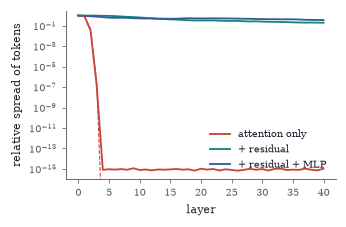

In [3]:
rng = np.random.default_rng(1); n, d, dk = 64, 32, 8; X0 = rng.normal(size=(n, d))
def attn(X, Wq, Wk, Wv):
    S = (X @ Wq) @ (X @ Wk).T / np.sqrt(dk); S -= S.max(1, keepdims=True); A = np.exp(S); A /= A.sum(1, keepdims=True); return A, A @ X @ Wv
def spread(X): return np.linalg.norm(X - X.mean(0)) / np.linalg.norm(X)
lnorm = lambda X: (X - X.mean(1, keepdims=True)) / X.std(1, keepdims=True)
Xa, Xr, Xm = X0.copy(), X0.copy(), X0.copy(); sa, sr, sm, bound = [1.0], [1.0], [1.0], [1.0]; tb = 1.0; s0 = spread(X0)
for l in range(40):
    Wq, Wk = rng.normal(size=(d, dk)) / np.sqrt(d), rng.normal(size=(d, dk)) / np.sqrt(d); Wv = rng.normal(size=(d, d)) / np.sqrt(d)
    W1 = rng.normal(size=(d, 4 * d)) * np.sqrt(2 / d); W2 = rng.normal(size=(4 * d, d)) / np.sqrt(4 * d)
    A, Y = attn(Xa, Wq, Wk, Wv); tb *= 0.5 * np.max(np.abs(A[:, None, :] - A[None, :, :]).sum(2)); Xa = Y; sa.append(spread(Xa) / s0); bound.append(tb)
    _, Y = attn(lnorm(Xr), Wq, Wk, Wv); Xr = Xr + Y; sr.append(spread(Xr) / s0)
    _, Y = attn(lnorm(Xm), Wq, Wk, Wv); Xm = Xm + Y; Xm = Xm + np.maximum(lnorm(Xm) @ W1, 0) @ W2; sm.append(spread(Xm) / s0)
fig, ax = plt.subplots(figsize=(W * 0.66, 1.95)); ax.semilogy(sa, color=RED, label="attention only"); ax.semilogy(sr, color=TEAL, label="+ residual"); ax.semilogy(sm, color=BLUE, label="+ residual + MLP")
ax.semilogy(bound, "--", color=RED, lw=0.7); ax.set_ylim(1e-16, 3); ax.set_xlabel("layer"); ax.set_ylabel("relative spread of tokens"); ax.legend(fontsize=6.5, frameon=False, loc="lower right")

In [4]:
rng = np.random.default_rng(0); n, dv = 1000, 4; s = rng.normal(size=n) * 300; Vv = rng.normal(size=(n, dv))
with np.errstate(over="ignore", invalid="ignore"): naive = (np.exp(s) @ Vv) / np.exp(s).sum()
m, l, o = -np.inf, 0.0, np.zeros(dv)
for blk in range(0, n, 128):
    sb, vb = s[blk:blk + 128], Vv[blk:blk + 128]; mb = sb.max(); lb = np.exp(sb - mb).sum(); ob = np.exp(sb - mb) @ vb
    mn = max(m, mb); l = np.exp(m - mn) * l + np.exp(mb - mn) * lb; o = np.exp(m - mn) * o + np.exp(mb - mn) * ob; m = mn
p = np.exp(s - s.max()); exact = p @ Vv / p.sum()
print("naive exp (overflows):", naive); print("online, 8 blocks:     ", np.round(o / l, 6)); print("stable reference:     ", np.round(exact, 6))

naive exp (overflows): [nan nan nan nan]
online, 8 blocks:      [-2.02499  -0.041009 -1.082972  0.820183]
stable reference:      [-2.02499  -0.041009 -1.082972  0.820183]


Associative memory in a matrix state. $n$ key–value pairs with random unit keys in $\R^{64}$ are written into a $64\times64$ state, then each value is retrieved with its key; relative retrieval error against $n$. Additive linear attention ($S=\sum v_jk_j^{T}$, red) suffers interference that grows like $\sqrt{n/N}$; one pass of the delta rule (blue) reduces it by writing only corrections; the least squares memory $S=VK^{+T}$ (black; for $n\le N$ it is the limit of repeated delta-rule passes) is exact up to $n=N=64$ and then degrades, since a $64\times64$ matrix cannot store more than $64$ independent associations.

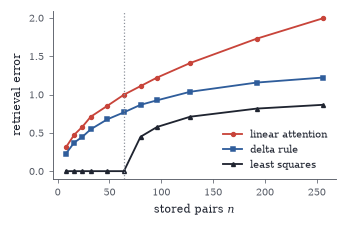

In [5]:
rng = np.random.default_rng(0); Nk = 64; ns = [8, 16, 24, 32, 48, 64, 80, 96, 128, 192, 256]; e1, e2, e3 = [], [], []
for n in ns:
    a, b, c = [], [], []
    for rep in range(6):
        K = rng.normal(size=(n, Nk)); K /= np.linalg.norm(K, axis=1, keepdims=True); Vm = rng.normal(size=(n, Nk)); S2 = np.zeros((Nk, Nk))
        for i in range(n): S2 = S2 + np.outer(Vm[i] - S2 @ K[i], K[i])
        S3 = Vm.T @ np.linalg.pinv(K.T); nv = np.linalg.norm(Vm)
        a.append(np.linalg.norm(K @ (Vm.T @ K).T - Vm) / nv); b.append(np.linalg.norm(K @ S2.T - Vm) / nv); c.append(np.linalg.norm(K @ S3.T - Vm) / nv)
    e1.append(np.mean(a)); e2.append(np.mean(b)); e3.append(np.mean(c))
fig, ax = plt.subplots(figsize=(W * 0.66, 1.95)); ax.plot(ns, e1, "o-", color=RED, ms=2.5, label="linear attention"); ax.plot(ns, e2, "s-", color=BLUE, ms=2.5, label="delta rule"); ax.plot(ns, e3, "^-", color=INK, ms=2.5, label="least squares")
ax.axvline(Nk, color=GRAY, ls=":", lw=0.8); ax.set_xlabel("stored pairs $n$"); ax.set_ylabel("retrieval error"); ax.legend(fontsize=6.3, frameon=False)

Low-rank adaptation of a linear model $y=Wx$ ($64\times64$) from pretrained weights $W_0$ to a task whose target differs from $W_0$ by a rank-$4$ matrix plus small full-rank noise. Left: training loss for full fine-tuning (black) and LoRA with ranks $1$, $2$, $4$, $8$ (all by gradient descent); LoRA with rank $4$ or more reaches the loss of the exact rank-$4$ change (dotted line), the remaining gap to full fine-tuning being the small full-rank noise, which full fine-tuning fits and a low-rank adapter cannot; ranks $1$ and $2$ stall higher. Right: singular values of the update $W-W_0$ learned by full fine-tuning: four large values carry the change, and the rest are small.

Text(0, 0.5, 'singular value of $W-W_0$')

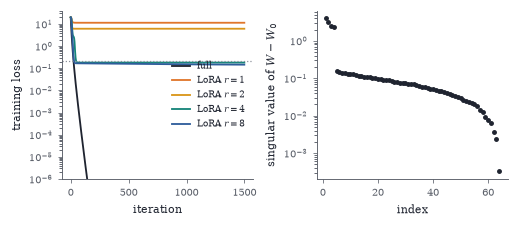

In [6]:
rng = np.random.default_rng(0); d = 64; W0 = rng.normal(size=(d, d)) / np.sqrt(d); Dl = rng.normal(size=(d, 4)) @ rng.normal(size=(4, d)) / d * 3; Wt = W0 + Dl + 0.01 * rng.normal(size=(d, d))
Xd = rng.normal(size=(d, 512)); Yd = Wt @ Xd; Nb = Xd.shape[1]
def loss(Wm): return 0.5 * np.mean(np.sum((Wm @ Xd - Yd) ** 2, 0))
def grad(Wm): return (Wm @ Xd - Yd) @ Xd.T / Nb
fig, axs = plt.subplots(1, 2, figsize=(W, 1.95)); T = 1500; eta = 0.1
Wf = W0.copy(); lf = []
for t in range(T): lf.append(loss(Wf)); Wf -= eta * grad(Wf)
axs[0].semilogy(lf, color=INK, label="full")
for r, c in [(1, ORANGE), (2, GOLD), (4, TEAL), (8, BLUE)]:
    B = np.zeros((d, r)); A = rng.normal(size=(r, d)) / np.sqrt(d); sc = 1.0; ll = []
    for t in range(T):
        Wm = W0 + sc * B @ A; ll.append(loss(Wm)); G = grad(Wm); B, A = B - eta * sc * G @ A.T, A - eta * sc * B.T @ G
    axs[0].semilogy(ll, color=c, label=f"LoRA $r={r}$")
axs[0].axhline(loss(W0 + Dl), color=GRAY, ls=":", lw=0.8); axs[0].set_ylim(1e-6, 2 * lf[0]); axs[0].set_xlabel("iteration"); axs[0].set_ylabel("training loss"); axs[0].legend(fontsize=5.8, frameon=False, loc="center right")
axs[1].semilogy(np.arange(1, d + 1), np.linalg.svd(Wf - W0, compute_uv=False), "o", color=INK, ms=2.2); axs[1].set_xlabel("index"); axs[1].set_ylabel("singular value of $W-W_0$")

Superposition in a toy model: five features compressed to two dimensions and reconstructed through a ReLU. Each panel shows the five columns of the trained $W$ as vectors in the plane, for features active with probability $p=1$ (dense), $0.3$ and $0.05$ (sparse). Dense: two features get nearly orthogonal directions and the others are almost ignored. Intermediate: four features in two antipodal pairs. Sparse: all five features, arranged as a regular pentagon; interference between them is tolerated because two features are rarely active together.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


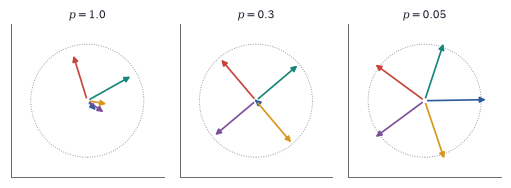

In [7]:
def toy(p, steps=8000, seed=0):
    g = np.random.default_rng(seed); Wt_ = g.normal(size=(2, 5)) * 0.3; bt = np.zeros(5); mo = [np.zeros((2, 5)), np.zeros(5)]; ve = [np.zeros((2, 5)), np.zeros(5)]
    for t in range(1, steps + 1):
        x = g.uniform(size=(5, 1024)) * (g.uniform(size=(5, 1024)) < p); h = Wt_ @ x; z = Wt_.T @ h + bt[:, None]; dl = 2 * (np.maximum(z, 0) - x) * (z > 0) / 1024
        Gs = [h @ dl.T + Wt_ @ dl @ x.T, dl.sum(1)]
        for i, P_ in enumerate((Wt_, bt)):
            mo[i] = 0.9 * mo[i] + 0.1 * Gs[i]; ve[i] = 0.999 * ve[i] + 0.001 * Gs[i] ** 2; P_ -= 1e-2 * (mo[i] / (1 - 0.9**t)) / (np.sqrt(ve[i] / (1 - 0.999**t)) + 1e-8)
    return Wt_, bt
fig, axs = plt.subplots(1, 3, figsize=(W, 1.6))
for ax, p in zip(axs, [1.0, 0.3, 0.05]):
    Wt_, bt = toy(p)
    for i in range(5): ax.annotate("", xy=Wt_[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=PALETTE[i], lw=1.1))
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls=":", color=GRAY, lw=0.6)); ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"$p={p}$", fontsize=7)

In [8]:
dk = 16; om = 10000.0 ** (-np.arange(dk // 2) * 2 / dk); rng = np.random.default_rng(0); q, k = rng.normal(size=dk), rng.normal(size=dk)
def R(m):
    M = np.zeros((dk, dk))
    for j, w in enumerate(om): c, s = np.cos(m * w), np.sin(m * w); M[2 * j:2 * j + 2, 2 * j:2 * j + 2] = [[c, -s], [s, c]]
    return M
z, wv = q[0::2] + 1j * q[1::2], k[0::2] + 1j * k[1::2]
for m, n in [(0, 5), (10, 15), (100, 105)]: print(f"m={m:3d}, n={n:3d}:  score {(R(m) @ q) @ (R(n) @ k):+.6f}   complex formula {np.real(np.sum(np.conj(z) * wv * np.exp(1j * (n - m) * om))):+.6f}")

m=  0, n=  5:  score +1.419499   complex formula +1.419499
m= 10, n= 15:  score +1.419499   complex formula +1.419499
m=100, n=105:  score +1.419499   complex formula +1.419499


In [9]:
rng = np.random.default_rng(1); n = 8; S = rng.normal(size=(n, n)) * 2; S[np.triu_indices(n, 1)] = -np.inf
A = np.exp(S - S.max(1, keepdims=True)); A /= A.sum(1, keepdims=True)
print("diagonal:", np.round(np.diag(A), 3)); print("singular values:", np.round(np.linalg.svd(A, compute_uv=False), 3))

diagonal: [1.    0.465 0.113 0.37  0.005 0.357 0.266 0.01 ]
singular values: [1.506e+00 9.690e-01 7.590e-01 4.530e-01 2.830e-01 9.400e-02 7.000e-03
 1.000e-03]


In [10]:
rng = np.random.default_rng(2); n, N, dv = 60, 4, 3; Qm, Km, Vm = rng.normal(size=(n, N)), rng.normal(size=(n, N)), rng.normal(size=(n, dv)); a = rng.uniform(0.8, 1.0, n)
S = np.zeros((dv, N)); Orec = np.zeros((n, dv))
for i in range(n): S = a[i] * S + np.outer(Vm[i], Km[i]); Orec[i] = S @ Qm[i]
cp = np.cumprod(a); Lm = np.tril(cp[:, None] / cp[None, :]); Mm = Lm * (Qm @ Km.T); Opar = Mm @ Vm
print("max difference recurrent vs parallel:", np.abs(Orec - Opar).max())
print("ranks of lower-left blocks M[i0:, :i0]:", [int(np.linalg.matrix_rank(Mm[i0:, :i0], tol=1e-8)) for i0 in (10, 20, 30, 40, 50)])

max difference recurrent vs parallel: 3.552713678800501e-15
ranks of lower-left blocks M[i0:, :i0]: [4, 4, 4, 4, 4]


In [11]:
rng = np.random.default_rng(3); d, k, r, alpha, eta = 50, 40, 6, 12.0, 0.1; G = rng.normal(size=(d, k)); A = rng.normal(size=(r, k)) / np.sqrt(k); B = np.zeros((d, r))
Bn = B - eta * (alpha / r) * G @ A.T; dW = (alpha / r) * (Bn @ A - B @ A); print("matches formula:", np.allclose(dW, -eta * alpha**2 / r**2 * G @ A.T @ A))
print("nonzero eigenvalues of A^T A:", np.round(np.linalg.eigvalsh(A.T @ A)[-r:], 3), "  (r/k =", round(r / k, 3), ")")

matches formula: True
nonzero eigenvalues of A^T A: [0.341 0.523 0.612 1.126 1.544 1.728]   (r/k = 0.15 )


In [12]:
rng = np.random.default_rng(4); d = 256
for m in (256, 2560, 25600):
    U = rng.normal(size=(m, d)).astype(np.float32); U /= np.linalg.norm(U, axis=1, keepdims=True); mx = 0.0
    for i0 in range(0, m, 2560):
        C = U[i0:i0 + 2560] @ U.T; idx = np.arange(i0, min(i0 + 2560, m)); C[idx - i0, idx] = 0; mx = max(mx, np.abs(C).max())
    print(f"m={m:6d}: max |cos| = {mx:.3f}   prediction {np.sqrt(2 * np.log(m * m / 2) / d):.3f}")

m=   256: max |cos| = 0.289   prediction 0.285
m=  2560: max |cos| = 0.311   prediction 0.342


m= 25600: max |cos| = 0.353   prediction 0.391
